In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install -r requirements.txt
!pip install ultralytics supervision

ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.2/107.2 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 42.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.7/409.7 kB 39.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 68.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.0/204.0 kB 22.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 11.6 MB/s eta 0:00:00


In [ ]:
import os

# Tạo thư mục dự án trên Drive (thay đổi đường dẫn nếu bạn lưu ở chỗ khác)
PROJECT_DIR = "/content/drive/MyDrive/carParking"
os.makedirs(PROJECT_DIR, exist_ok=True)

# Chuyển hướng làm việc vào thư mục này
%cd {PROJECT_DIR}

# Tạo các thư mục con cần thiết
os.makedirs("models", exist_ok=True)   # Nơi chứa best.pt
os.makedirs("data", exist_ok=True)     # Nơi chứa video thật
os.makedirs("out", exist_ok=True)

/content/drive/MyDrive/carParking


In [ ]:
  import cv2
  import json
  import numpy as np
  from ultralytics import YOLO

  VIDEO_PATH = "/content/drive/MyDrive/carParking/data/carParking3.mp4"

  cap_init = cv2.VideoCapture(VIDEO_PATH)
  ret_init, first_frame = cap_init.read()
  cap_init.release()

  if not ret_init:
      raise Exception(f"Không đọc được video từ đường dẫn: {VIDEO_PATH}")

  # Kích thước video gốc
  orig_h, orig_w = first_frame.shape[:2]
  print(f"✓ Kích thước video gốc: {orig_w} x {orig_h}")

  # Lưu lại frame đầu tiên đúng độ phân giải gốc để làm tọa độ vẽ bounding box
  OUTPUT_PNG_PATH = "first_frame.png"
  cv2.imwrite(OUTPUT_PNG_PATH, first_frame)
  print(f"✓ Đã lưu file PNG đúng chuẩn kích thước video tại: {OUTPUT_PNG_PATH}\n")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
✓ Kích thước video gốc: 960 x 540
✓ Đã lưu file PNG đúng chuẩn kích thước video tại: first_frame.png



In [4]:
import json

# Đường dẫn file JSON trên Google Drive của bạn
JSON_PATH = "/content/drive/MyDrive/carParking/roboflow_output3.json"

# Đọc dữ liệu từ file JSON
with open(JSON_PATH, "r") as f:
    roboflow_data = json.load(f)

# Kiểm tra nếu dữ liệu là dict chứa key "predictions" hay là một list trực tiếp
preds = roboflow_data.get("predictions", roboflow_data) if isinstance(roboflow_data, dict) else roboflow_data

slots = []
for idx, pred in enumerate(preds, start=1):
    cx = pred["x"]
    cy = pred["y"]
    w = pred["width"]
    h = pred["height"]

    # Tính 4 góc Bounding Box từ Center X, Center Y, Width, Height
    x1 = int(cx - w / 2)
    y1 = int(cy - h / 2)
    x2 = int(cx + w / 2)
    y2 = int(cy + h / 2)

    # Tạo Polygon 4 đỉnh (theo chiều kim đồng hồ)
    coords = [
        [x1, y1],  # Góc trên - trái
        [x2, y1],  # Góc trên - phải
        [x2, y2],  # Góc dưới - phải
        [x1, y2]   # Góc dưới - trái
    ]

    slots.append({
        "id": idx,
        "coordinates": coords
    })

# Lưu ra file slots.json
with open("slots.json", "w") as f:
    json.dump(slots, f, indent=2)

print(f"✅ Đã chuyển đổi thành công {len(slots)} ô đỗ sang file slots.json!")

✅ Đã chuyển đổi thành công 95 ô đỗ sang file slots.json!



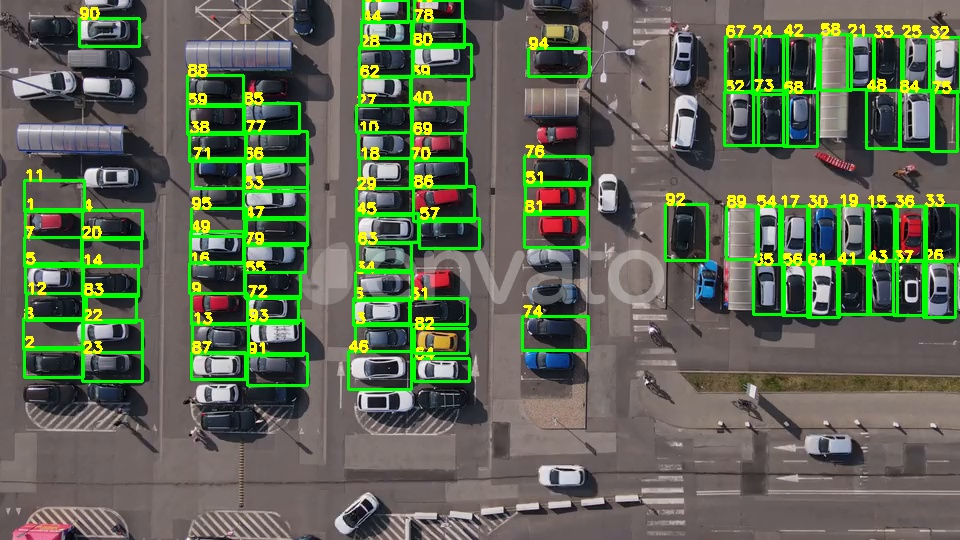

In [5]:
import cv2, json, base64
import IPython.display as display

# 1. Đường dẫn video và file slots.json vừa tạo
VIDEO_PATH = "/content/drive/MyDrive/carParking/data/carParking3.mp4"  # Thay bằng tên video của bạn
SLOTS_PATH = "/content/slots.json"

# Read frame 0
cap = cv2.VideoCapture(VIDEO_PATH)
ok, frame = cap.read()
cap.release()

if not ok:
    raise ValueError(f"Không thể đọc video tại {VIDEO_PATH}")

# Read slots
with open(SLOTS_PATH, "r") as f:
    slots = json.load(f)

# 2. Vẽ tất cả ô đỗ từ slots.json lên frame
import numpy as np

img_check = frame.copy()
for s in slots:
    pts = np.array(s["coordinates"], np.int32)
    # Vẽ viền ô đỗ màu xanh lá
    cv2.polylines(img_check, [pts], True, (0, 255, 0), 2)
    # In ID của ô đỗ
    cv2.putText(img_check, str(s["id"]), tuple(pts[0]),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 2)

# 3. Mã hóa sang Base64 và hiển thị trực tiếp trong Notebook
_, buffer = cv2.imencode('.jpg', img_check)
img_b64 = base64.b64encode(buffer).decode('utf-8')

html_code = f"""
<h3>Hình ảnh kiểm tra vị trí các ô đỗ (Tổng số: {len(slots)} ô)</h3>
<img src="data:image/jpeg;base64,{img_b64}" style="max-width: 100%; border: 2px solid #333;" />
"""
display.display(display.HTML(html_code))

In [14]:
import json

SLOTS_PATH = "/content/slots.json"

# 1. Nhập danh sách các ID ô đỗ bạn muốn XÓA vào đây
REMOVE_IDS = [58]  # Thay bằng các số ID thừa hiển thị trên hình của bạn

# 2. Đọc file slots.json
with open(SLOTS_PATH, "r") as f:
    slots = json.load(f)

print(f"Tổng số ô ban đầu: {len(slots)}")

# 3. Lọc bỏ các ô nằm trong danh sách REMOVE_IDS
filtered_slots = [s for s in slots if s["id"] not in REMOVE_IDS]

# 4. Đánh lại ID theo thứ tự liên tục 1, 2, 3... (tránh bị nhảy số)
for idx, s in enumerate(filtered_slots, start=1):
    s["id"] = idx

# 5. Lưu lại file slots.json
with open(SLOTS_PATH, "w") as f:
    json.dump(filtered_slots, f, indent=2)

print(f"✅ Đã xóa {len(slots) - len(filtered_slots)} ô đỗ có ID: {REMOVE_IDS}")
print(f"✅ Số ô đỗ còn lại: {len(filtered_slots)} (đã đánh lại ID liên tục)")

Tổng số ô ban đầu: 119
✅ Đã xóa 1 ô đỗ có ID: [58]
✅ Số ô đỗ còn lại: 118 (đã đánh lại ID liên tục)


Kích thước video: 960 x 540
Đã nạp thành công 118 ô đỗ hiện có từ /content/slots.json



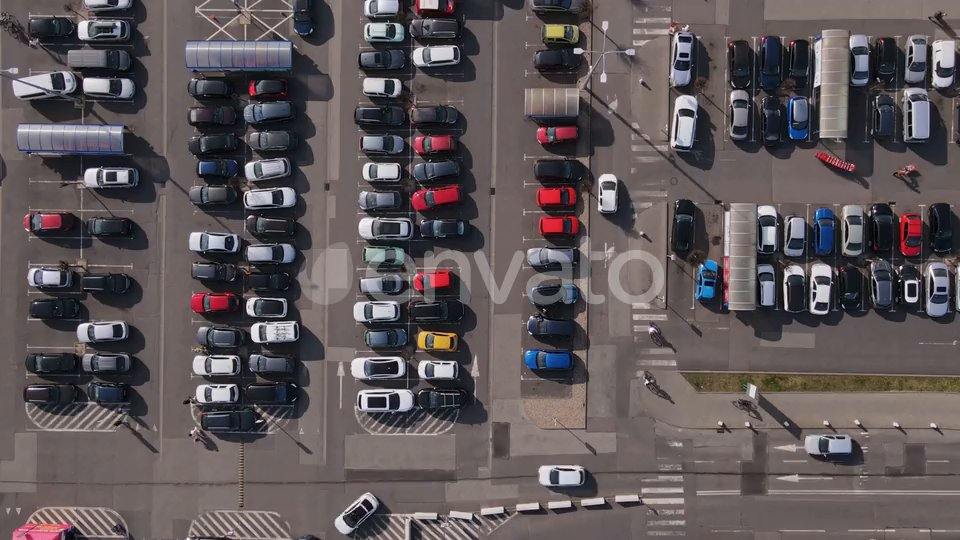


✓ ĐÃ CẬP NHẬT FILE SLOTS.JSON
Tổng số ô đỗ: 119
Đường dẫn file: /content/slots.json


In [15]:
import cv2
import json
import base64
import os
from google.colab import output
from IPython.display import display, HTML
from PIL import Image
import io

# ============================================
# CẤU HÌNH ĐƯỜNG DẪN FILE & VIDEO
# ============================================
VIDEO_PATH = "/content/drive/MyDrive/carParking/data/carParking3.mp4"   # Thay đường dẫn video thật của bạn
SLOT_FILE = "/content/slots.json"              # File slots hiện tại cần nạp & bổ sung

# Read frame 0
cap = cv2.VideoCapture(VIDEO_PATH)
ret, frame = cap.read()
cap.release()

if not ret:
    raise Exception(f"Không đọc được video từ {VIDEO_PATH}")

original_height, original_width = frame.shape[:2]
print(f"Kích thước video: {original_width} x {original_height}")

# ============================================
# ĐỌC CÁC Ô ĐỖ ĐÃ CÓ TRONG SLOTS.JSON (NẾU CÓ)
# ============================================
existing_slots = []
if os.path.exists(SLOT_FILE):
    try:
        with open(SLOT_FILE, "r", encoding="utf-8") as f:
            existing_slots = json.load(f)
        print(f"Đã nạp thành công {len(existing_slots)} ô đỗ hiện có từ {SLOT_FILE}")
    except Exception as e:
        print(f"Lỗi đọc file slots cũ: {e}")

# Chuyển đổi frame thành Base64
frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
image = Image.fromarray(frame_rgb)

MAX_WIDTH = 1200
display_width = min(original_width, MAX_WIDTH)
display_height = int(original_height * display_width / original_width)
image_display = image.resize((display_width, display_height))

buffer = io.BytesIO()
image_display.save(buffer, format="JPEG", quality=85)
image_base64 = base64.b64encode(buffer.getvalue()).decode("utf-8")

# ============================================
# JAVASCRIPT GIAO DIỆN CLICK BỔ SUNG Ô
# ============================================
html = f"""
<div style="font-family: Arial;">

<h3>🅿️ ĐÁNH DẤU BỔ SUNG CÁC Ô ĐỖ XE CÒN THIẾU</h3>

<p>
<b>Hướng dẫn:</b> Các ô màu xanh lá đã có sẵn từ file. Để vẽ ô mới, click <b>góc thứ nhất</b> ➔ click <b>góc đối diện</b>.
</p>

<div style="margin-bottom:10px;">
<button onclick="undoLast()" style="padding:8px 15px; margin-right:5px; cursor:pointer;">
↩️ Xóa ô vừa vẽ
</button>

<button onclick="finishSlots()" style="padding:8px 15px; background-color:#28a745; color:white; border:none; border-radius:4px; cursor:pointer;">
✅ LƯU ĐÈ VÀO SLOTS.JSON
</button>
</div>

<div style="border:2px solid #333; display:inline-block; position:relative;">
<canvas id="parkingCanvas" width="{display_width}" height="{display_height}" style="cursor:crosshair;">
</canvas>
</div>

<p id="status">
Tổng số ô hiện tại: <b>{len(existing_slots)}</b> ô
</p>

<script>
const canvas = document.getElementById("parkingCanvas");
const ctx = canvas.getContext("2d");
const img = new Image();

const originalWidth = {original_width};
const originalHeight = {original_height};

const scaleX = originalWidth / canvas.width;
const scaleY = originalHeight / canvas.height;

// Nạp danh sách ô đã có sẵn từ Python
let slots = {json.dumps(existing_slots)};
let initialCount = slots.length;
let currentPoints = [];

img.onload = function() {{
    redraw();
}};

img.src = "data:image/jpeg;base64,{image_base64}";

canvas.addEventListener("click", function(event) {{
    const rect = canvas.getBoundingClientRect();
    const x = event.clientX - rect.left;
    const y = event.clientY - rect.top;

    currentPoints.push({{ x: x, y: y }});

    // Vẽ chấm tròn điểm click
    ctx.fillStyle = "yellow";
    ctx.beginPath();
    ctx.arc(x, y, 4, 0, 2 * Math.PI);
    ctx.fill();

    // Đủ 2 điểm góc ➔ Tạo ô đỗ mới
    if (currentPoints.length === 2) {{
        const p1 = currentPoints[0];
        const p2 = currentPoints[1];

        const x1 = Math.round(Math.min(p1.x, p2.x) * scaleX);
        const y1 = Math.round(Math.min(p1.y, p2.y) * scaleY);
        const x2 = Math.round(Math.max(p1.x, p2.x) * scaleX);
        const y2 = Math.round(Math.max(p1.y, p2.y) * scaleY);

        const newId = slots.length + 1;

        // Lưu dạng Polygon 4 góc tương thích với pipeline code
        slots.push({{
            "id": newId,
            "coordinates": [
                [x1, y1],
                [x2, y1],
                [x2, y2],
                [x1, y2]
            ]
        }});

        currentPoints = [];
        redraw();
    }}
}});

function redraw() {{
    ctx.drawImage(img, 0, 0, canvas.width, canvas.height);

    for (let i = 0; i < slots.length; i++) {{
        const s = slots[i];
        let x1, y1, x2, y2;

        // Xử lý tọa độ từ coordinates
        if (s.coordinates && s.coordinates.length >= 4) {{
            x1 = s.coordinates[0][0] / scaleX;
            y1 = s.coordinates[0][1] / scaleY;
            x2 = s.coordinates[2][0] / scaleX;
            y2 = s.coordinates[2][1] / scaleY;
        }} else {{
            continue;
        }}

        // Phân biệt ô cũ và ô vừa vẽ thêm bằng màu sắc
        if (i < initialCount) {{
            ctx.strokeStyle = "#00FF00"; // Màu xanh lá cho ô cũ
        }} else {{
            ctx.strokeStyle = "#FFD700"; // Màu vàng cho ô mới vẽ
        }}

        ctx.lineWidth = 2;
        ctx.strokeRect(x1, y1, x2 - x1, y2 - y1);

        // Hiển thị ID ô
        ctx.fillStyle = "yellow";
        ctx.font = "bold 16px Arial";
        ctx.fillText(s.id, x1 + 4, y1 + 18);
    }}

    document.getElementById("status").innerHTML =
        "Tổng số ô: <b>" + slots.length + "</b> (Cũ: " + initialCount + " | Mới vẽ: " + (slots.length - initialCount) + ")";
}}

function undoLast() {{
    if (slots.length <= initialCount) {{
        alert("Không thể xóa các ô cũ đã nạp sẵn!");
        return;
    }}
    slots.pop();
    currentPoints = [];
    redraw();
}}

async function finishSlots() {{
    google.colab.kernel.invokeFunction(
        'notebook.saveSlots',
        [JSON.stringify(slots, null, 2)],
        {{}}
    );

    document.getElementById("status").innerHTML =
        "✅ ĐÃ LƯU THÀNH CÔNG " + slots.length + " Ô VÀO SLOTS.JSON!";
}}
</script>
</div>
"""

# ============================================
# HÀM LƯU FILE VÀO SLOTS.JSON
# ============================================
def save_slots_from_js(slots_json):
    parking_slots = json.loads(slots_json)

    # Cập nhật đánh lại ID theo thứ tự 1..N
    for idx, s in enumerate(parking_slots, start=1):
        s["id"] = idx

    with open(SLOT_FILE, "w", encoding="utf-8") as f:
        json.dump(parking_slots, f, indent=2, ensure_ascii=False)

    print("\n================================")
    print("✓ ĐÃ CẬP NHẬT FILE SLOTS.JSON")
    print("================================")
    print("Tổng số ô đỗ:", len(parking_slots))
    print("Đường dẫn file:", SLOT_FILE)

output.register_callback("notebook.saveSlots", save_slots_from_js)
display(HTML(html))

In [17]:
!pip install lap==0.5.13


In [18]:
import sys
import os
from pathlib import Path

PROJECT_PATH = "/content/drive/MyDrive/carParking"

if os.path.exists(PROJECT_PATH):
    sys.path.append(PROJECT_PATH)
    os.chdir(PROJECT_PATH)

import argparse
import csv
import json
import time

import cv2
import numpy as np
from ultralytics import YOLO
from occupancy import SlotEngine, make_slot


# ==========================================
# CẤU HÌNH
# ==========================================

slots_path = "/content/slots.json"

if not os.path.exists(slots_path):
    slots_path = os.path.join(PROJECT_PATH, "slots.json")

sys.argv = [
    "parking_monitor.py",
    "--video", "/content/drive/MyDrive/carParking/data/carParking3.mp4",
    "--weights", "/content/drive/MyDrive/carParking/models/best11n.pt",
    "--slots", slots_path,
    "--classes", "car",
    "--imgsz", "1920",
    "--conf", "0.5",
    "--theta", "0.35",
    "--window", "9",
    "--dwell", "15",
    "--out", "out/result3.mp4",
    "--log", "out/log3.csv"
]

ap = argparse.ArgumentParser()
ap.add_argument("--video", required=True)
ap.add_argument("--weights", default="best.pt")
ap.add_argument("--slots", default="slots.json")
ap.add_argument("--classes", nargs="+", default=None)
ap.add_argument("--imgsz", type=int, default=960)
ap.add_argument("--conf", type=float, default=0.25)
ap.add_argument("--tracker", default="bytetrack.yaml")
ap.add_argument("--theta", type=float, default=0.35)
ap.add_argument("--window", type=int, default=9)
ap.add_argument("--dwell", type=int, default=15)
ap.add_argument("--move-frac", type=float, default=0.15)
ap.add_argument("--out", default="out/result3.mp4")
ap.add_argument("--log", default="out/log3.csv")
ap.add_argument("--show", action="store_true")

args = ap.parse_args()

Path(args.out).parent.mkdir(parents=True, exist_ok=True)
Path(args.log).parent.mkdir(parents=True, exist_ok=True)


# ==========================================
# ĐỌC CÁC Ô ĐỖ
# ==========================================

slots = [
    make_slot(s["id"], s["coordinates"])
    for s in json.loads(Path(args.slots).read_text())
]

pts_cache = {
    s["id"]: np.array(s["coordinates"], np.int32)
    for s in slots
}

engine = SlotEngine(
    slots,
    args.theta,
    args.window,
    args.dwell,
    args.move_frac
)


# ==========================================
# KHỞI TẠO YOLO
# ==========================================

model = YOLO(args.weights)

wanted = None

if args.classes:
    wanted = {
        i for i, n in model.names.items()
        if n in set(args.classes)
    }

    if not wanted:
        raise SystemExit(
            f"Không có class nào khớp {args.classes}. "
            f"model.names = {model.names}"
        )

print("Classes:", {
    i: model.names[i]
    for i in (wanted if wanted is not None else model.names)
})


# ==========================================
# ĐỌC VIDEO
# ==========================================

cap = cv2.VideoCapture(args.video)

if not cap.isOpened():
    raise SystemExit(f"Không thể mở video: {args.video}")

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps_in = cap.get(cv2.CAP_PROP_FPS) or 25

ok, first_frame = cap.read()

if not ok:
    raise SystemExit("Không thể đọc video đầu vào!")

H, W = first_frame.shape[:2]

print(f"Độ phân giải video gốc: {W}x{H}")

cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

writer = cv2.VideoWriter(
    args.out,
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps_in,
    (W, H)
)

if not writer.isOpened():
    cap.release()
    raise SystemExit(f"Không thể tạo video đầu ra: {args.out}")

logf = open(args.log, "w", newline="", encoding="utf-8")
log = csv.writer(logf)

log.writerow([
    "frame",
    "slot_id",
    "max_ratio",
    "raw",
    "track",
    "final",
    "track_id"
])


# ==========================================
# MÀU SẮC (CHỈ 2 MÀU: ĐỎ & XANH LÁ)
# OpenCV sử dụng thứ tự BGR
# ==========================================

CAR_COLOR = (255, 200, 0)       # Xanh da trời cho xe

COLOR_OCCUPIED = (0, 0, 255)    # Đỏ (Có xe)
COLOR_EMPTY = (0, 255, 0)       # Xanh lá (Trống)

# Độ đậm của màu phủ: 0.0 = trong suốt, 1.0 = màu đặc
FILL_ALPHA = 0.40

lat = []
frame_idx = 0

print(f"Bắt đầu xử lý video ({total_frames} frames)...")


# ==========================================
# VÒNG LẶP XỬ LÝ VIDEO
# ==========================================

while True:
    ok, frame = cap.read()

    if not ok:
        break

    t0 = time.perf_counter()

    # --------------------------------------
    # 1. YOLO + BYTETRACK
    # --------------------------------------

    res = model.track(
        frame,
        persist=True,
        tracker=args.tracker,
        imgsz=args.imgsz,
        conf=args.conf,
        verbose=False
    )[0]

    vehicles = []
    b = res.boxes

    if b is not None and b.id is not None:
        for bb, tid, c in zip(
            b.xyxy.cpu().numpy(),
            b.id.int().cpu().numpy(),
            b.cls.int().cpu().numpy()
        ):
            if wanted is None or int(c) in wanted:
                vehicles.append({
                    "id": int(tid),
                    "box": tuple(map(float, bb))
                })

    # --------------------------------------
    # 2. CẬP NHẬT TRẠNG THÁI Ô ĐỖ
    # --------------------------------------

    results = engine.update(vehicles)

    lat.append((time.perf_counter() - t0) * 1000)

    # --------------------------------------
    # 3. VẼ BOUNDING BOX XE - KHÔNG HIỆN ID
    # --------------------------------------

    for v in vehicles:
        x1, y1, x2, y2 = map(int, v["box"])

        cv2.rectangle(
            frame,
            (x1, y1),
            (x2, y2),
            CAR_COLOR,
            2,
            lineType=cv2.LINE_AA
        )

    # --------------------------------------
    # 4. TÔ MÀU NHẠT CHO CÁC Ô ĐỖ (ĐỎ / XANH LÁ)
    # --------------------------------------

    overlay = frame.copy()
    empty = 0

    for r in results:
        sid = r["slot_id"]
        pts = pts_cache[sid]

        # Ghi log, vẫn giữ track_id trong CSV
        log.writerow([
            frame_idx,
            sid,
            f"{r['max_ratio']:.4f}",
            int(r["raw"]),
            int(r["track"]),
            int(r["final"]),
            r["track_id"] if r["track_id"] is not None else ""
        ])

        if not r["final"]:
            empty += 1

        # Gán màu theo trạng thái (r["final"] == 1 -> Đỏ, ngược lại -> Xanh lá)
        color = COLOR_OCCUPIED if r["final"] else COLOR_EMPTY

        cv2.fillPoly(
            overlay,
            [pts],
            color,
            lineType=cv2.LINE_AA
        )

    # Trộn lớp màu với ảnh gốc (Đã sửa lỗi công thức alpha)
    cv2.addWeighted(
         overlay,
         FILL_ALPHA,
         frame,
         1.0 - FILL_ALPHA,
         0,
         frame
    )

    # --------------------------------------
    # 5. VẼ VIỀN VÀ NHÃN Ô ĐỖ
    # --------------------------------------

    for r in results:
        sid = r["slot_id"]
        pts = pts_cache[sid]

        color = COLOR_OCCUPIED if r["final"] else COLOR_EMPTY

        # Viền ô cùng màu với trạng thái
        cv2.polylines(
            frame,
            [pts],
            True,
            color,
            2,
            lineType=cv2.LINE_AA
        )

        # Chỉ hiện mã ô
        cv2.putText(
            frame,
            str(sid),
            (
                int(pts[0][0]),
                max(int(pts[0][1]) - 5, 20)
            ),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            color,
            1,
            lineType=cv2.LINE_AA
        )

    # --------------------------------------
    # 6. HIỂN THỊ SỐ Ô TRỐNG
    # --------------------------------------

    cv2.putText(
        frame,
        f"Available: {empty}/{len(slots)}",
        (30, 50),
        cv2.FONT_HERSHEY_SIMPLEX,
        1.0,
        (255, 255, 255),
        2,
        lineType=cv2.LINE_AA
    )

    # --------------------------------------
    # 7. GHI VIDEO
    # --------------------------------------

    writer.write(frame)
    frame_idx += 1

    if frame_idx % 50 == 0 or frame_idx == total_frames:
        pct = (
            frame_idx / total_frames * 100
            if total_frames > 0 else 0
        )

        print(
            f"Đã xử lý: {frame_idx}/{total_frames} "
            f"frames ({pct:.1f}%)"
        )


# ==========================================
# GIẢI PHÓNG TÀI NGUYÊN
# ==========================================

cap.release()
writer.release()
logf.close()
cv2.destroyAllWindows()


# ==========================================
# THỐNG KÊ HIỆU NĂNG
# ==========================================

lat = np.array(lat)

if len(lat) > 0:
    summary = {
        "frames": frame_idx,
        "latency_ms_mean": float(lat.mean()),
        "latency_ms_p50": float(np.percentile(lat, 50)),
        "latency_ms_p95": float(np.percentile(lat, 95)),
        "fps_mean": float(1000 / lat.mean()),
        "params": vars(args)
    }

    Path(args.log).with_suffix(".summary.json").write_text(
        json.dumps(summary, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )

    print("\nHOÀN THÀNH!")
    print(f"Video: {args.out}")
    print(f"Log: {args.log}")

    print(json.dumps(
        {k: v for k, v in summary.items() if k != "params"},
        indent=2,
        ensure_ascii=False
    ))
else:
    print("Video không có frame nào được xử lý.")

Classes: {0: 'car'}
Độ phân giải video gốc: 960x540
Bắt đầu xử lý video (175 frames)...
Đã xử lý: 50/175 frames (28.6%)
Đã xử lý: 100/175 frames (57.1%)
Đã xử lý: 150/175 frames (85.7%)
Đã xử lý: 175/175 frames (100.0%)

HOÀN THÀNH!
Video: out/result3.mp4
Log: out/log3.csv
{
  "frames": 175,
  "latency_ms_mean": 192.15209630285696,
  "latency_ms_p50": 164.28129300004457,
  "latency_ms_p95": 192.19135849999697,
  "fps_mean": 5.204210722863354
}
